# Single-kidney glomerular filtration rate

This example illustrates the use of the `dcmri.AortaKidneys` model 
for measurement of single-kidney glomerular filtration rate (SK-GFR). 

The script uses data from a validation study comparing MRI-derived 
measurement of SK-GFR against reference measurements performed with 
radio-isotopes (Basak et al 2018). The study used 124 historical 
datasets collected in between the years 2000 and 2010 at 1 Tesla and 
3 Tesla MRI. 

The study was funded by 
`Kidney Research UK <https://www.kidneyresearchuk.org/>`_.

**Reference**

Basak S, Buckley DL, Chrysochou C, Banerji A, Vassallo D, Odudu A, Kalra PA, 
Sourbron SP. Analytical validation of single-kidney glomerular filtration 
rate and split renal function as measured with magnetic resonance renography. 
Magn Reson Imaging. 2019 Jun;59:53-60. doi: 10.1016/j.mri.2019.03.005. 
`[URL] <https://pubmed.ncbi.nlm.nih.gov/30849485/>`_.

First we set up the notebook so plots appear in-line

In [1]:
%matplotlib inline

and define a location to save the outputs

In [2]:
outputdir = r'C:\Users\md1spsx\Documents\Data\dcmri\skgfr_validation_wholebody'

The model that we will use predicts signals in aorta and both kidneys at the same time. Since we don't have echo times we will configure it to predict without T2* relaxation effects:

In [3]:
import dcmri as dc

model = dc.InverseAortaKidneys(
    heartlung='chain',         # Smoother first pass data
    organs='2cxm',              # Long acquisition times reveal extravasation
    kidneys='2CF',              # Intracellular agent
    baseline='measured',        # Data are available on precontrast T1
    sequence='ZTE-3D-SPGR-SS',
    t2s_relaxation_ao=None,     # No T2* relaxation with TE=0
    t2s_relaxation_lk=None,     # No T2* relaxation with TE=0
    t2s_relaxation_rk=None,     # No T2* relaxation with TE=0
    estimate_bat='custom',      # Use the dedicated BAT estimator
)

Before we proceed to analyse all cases, lets fit a single subject so we can look at the results. The data are part of the dcmri example datasets so we can use the built-in loader to read them.

In [4]:
# Load all data from the pre-treatment visit
data = dc.load_kruk(visit='pre')

# Get data from the first subject
data_subj_0 = data['099']

# Fit the model to the data
result_subj_0 = model(data_subj_0, verbose=2)

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         1.8209e+03                                    8.44e+03    
       1              2         2.6153e+02      1.56e+03       6.14e-01       1.03e+03    
       2              3         2.6241e+01      2.35e+02       5.50e-01       1.36e+02    
       3              4         4.5445e+00      2.17e+01       3.58e-01       1.26e+01    
       4              5         3.7224e+00      8.22e-01       3.11e-01       8.23e+01    
       5              6         2.3184e+00      1.40e+00       2.10e-01       1.48e+01    
       6              8         2.1523e+00      1.66e-01       8.63e-02       5.99e+01    
       7              9         1.9323e+00      2.20e-01       8.77e-02       1.29e+01    
       8             11         1.8746e+00      5.77e-02       4.36e-02       1.11e+01    
       9             12         1.7968e+00      7.78e-02       8.51e-02       3.39e+01    

Let's check the fit:

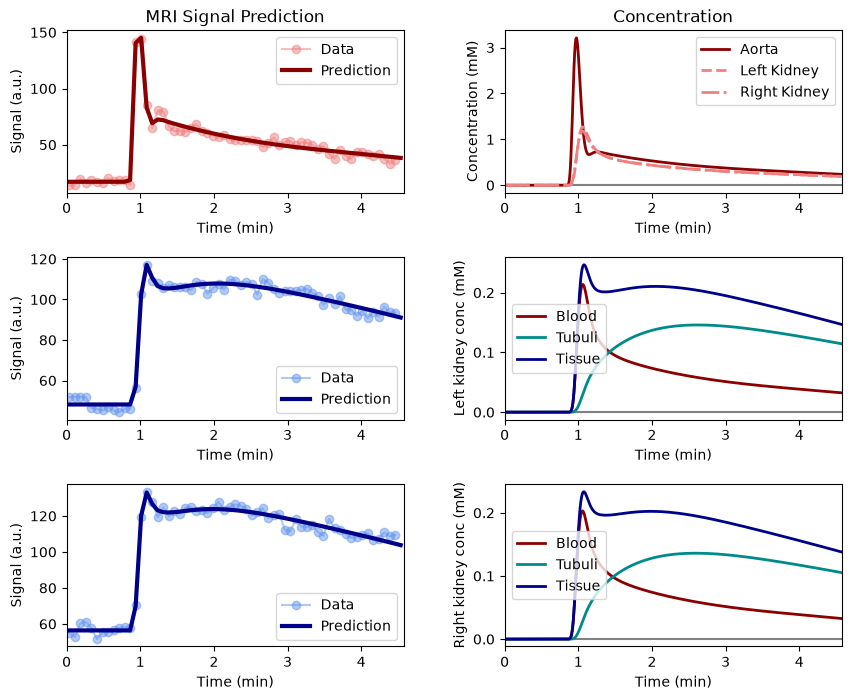

In [5]:
model.plot(data_subj_0, result_subj_0)

This shows that the model describes the data well, and concentrations are in an expected range. Next we can check that all parameters are well-determined:

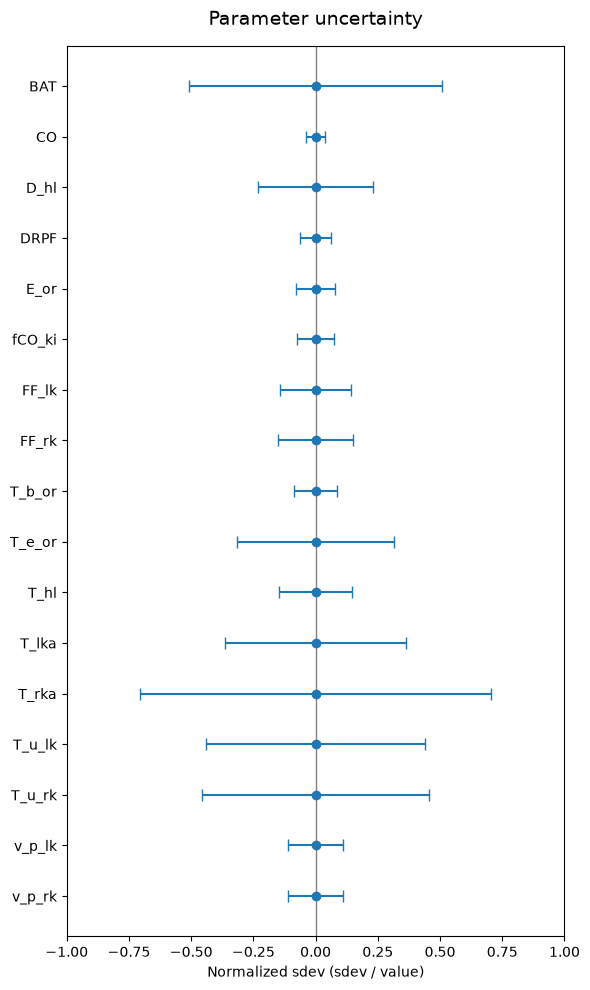

In [6]:
model.plot_pvar(result_subj_0, xlim=[-1, 1])

The transit times in the left and right renal artery are fairly imprecise, but also less of interest. The tubular transit times too are relatively imprecise - possibly due to the relatively short acquisition times which do not fully resolve the clearance of contrast agent from the tubuli. We can also check if there are any dependencies between the parameters:

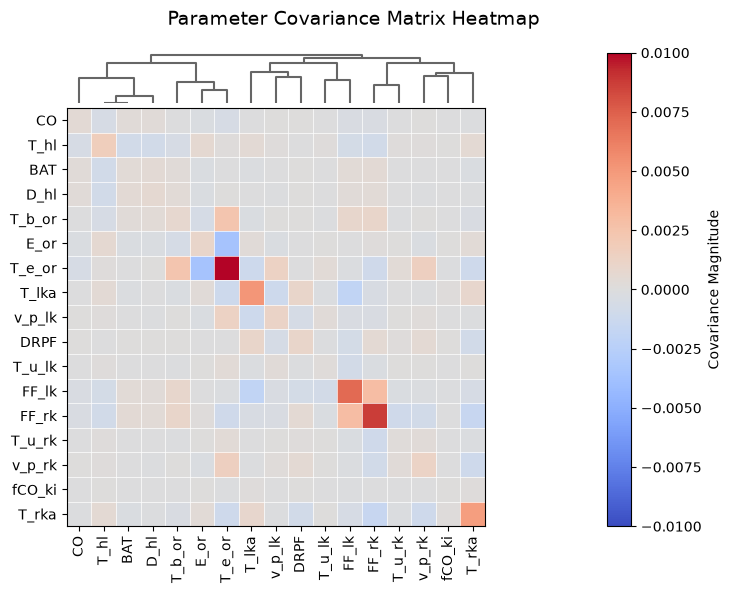

In [7]:
model.plot_pcov(result_subj_0, vmin=-0.01, vmax=0.01)

This does not show any catastrophic correlations. Let's have a look at the measurements:

In [8]:
model.print(result_subj_0, digits=3)

+-----------------------------------------------------------------------------------------------------------------------------------------+
|                                                                Quantities                                                               |
+--------+---------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| Key    | Value   | Unit       | Name                                                   | Group           | Bounds       | DICOM | OSIPI |
+--------+---------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| BAT    | 49.5    | sec        | bolus arrival time                                     | indicator       | (-30, 30)    |       |       |
+--------+---------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| CO     | 280.0   |

There are no unexpected values here, except for the cardiac output which appears overestimated with this protocol. It probably does not affect the kidney measurements as the renal fraction of the cardiac output is low to compensate. Kidney perfusion values are if anything on the low side but this is not un expected in patients with chronic kidney disease.

## Population-level analysis

Now that the basic modelling is verified in a case, lets proceed to fitting the population. We'll use a helper function to hide the bureaucracy:

In [9]:
from ntbk_dcmri.skgfr_validation_wholebody import fit_all_data

results = fit_all_data(model, outputdir)

The result is a pandas dataframe in long forwat. Lets plot the MRI SKGFR values against the reference

In [10]:
from ntbk_dcmri.skgfr_validation_wholebody import plot_skgfr

# Plot the full range
plot_skgfr(results, outputdir, 'skgfr_all.png')

# plot a detail
plot_skgfr(results, outputdir, 'skgfr_detail.png', vmax=80)

Lets have a look at the plots

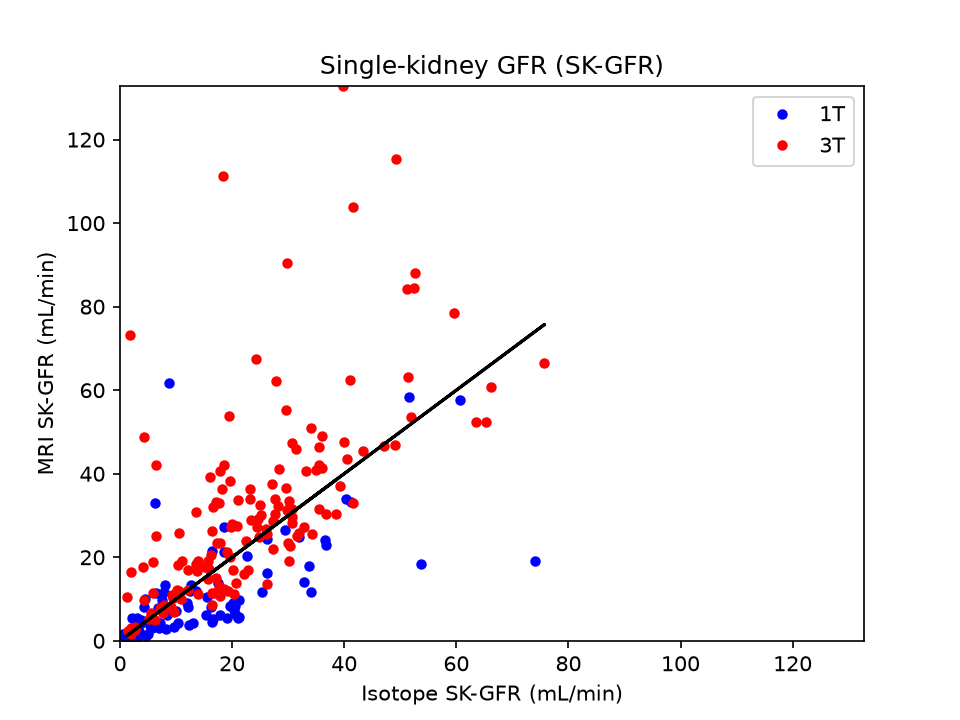

In [11]:
import os
from IPython.display import Image, display

png = os.path.join(outputdir, 'skgfr_all.png')
display(Image(png))

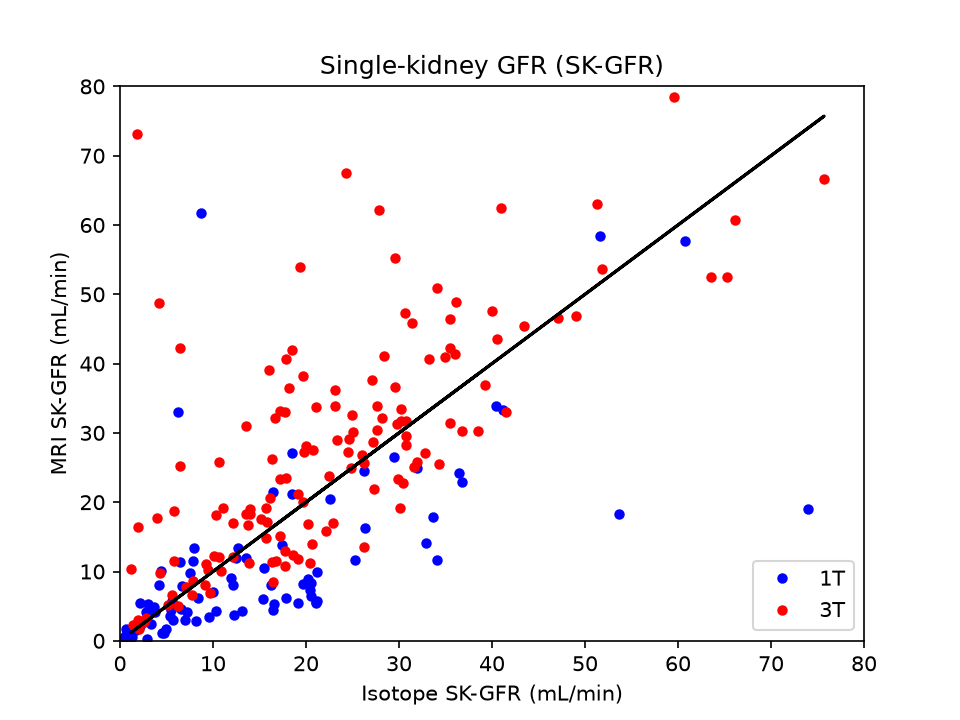

In [12]:
import os
from IPython.display import Image, display

png = os.path.join(outputdir, 'skgfr_detail.png')
display(Image(png))

The results confirm the conclusion from the original study that the precision of MR-derived SK-GFR with these historical data was too low for clinical use. The exact numerical values are different from those in the original study, showing the importance of  implementation detail. 

If we compute the bias and precison we find similar values as in the original paper, which found a bias of 1 mL/min and an error of +/- 29 mL/min

In [14]:
from ntbk_dcmri.skgfr_validation_wholebody import print_error

print_error(results)


Single-kidney GFR
-----------------
Bias of an MRI-based SK-GFR measurement: 4.00 ± 2.00 mL/min
Error on a single bias-corrected SK-GFR measurement (95% CI): ± 33.0 mL/min
